<a href="https://colab.research.google.com/github/davide-ario/BNN/blob/main/BNN_returns_to_education_card.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Returns to schooling with rich controls: Card (1995) data

This notebook repeats the analysis of
[`BNN_returns_to_education.ipynb`](BNN_returns_to_education.ipynb) on the
data of Card (1995), *Using geographical variation in college proximity to
estimate the return to schooling*. The CPS example had only age, gender and
region as controls. Here we have:

* family background (parents' education, family structure at age 14);
* **ability proxies**: an IQ score and a test of "knowledge of the world of
  work" (KWW);
* an **instrument**, whether the respondent grew up near a four-year
  college, which Card used to estimate a causal return.

This lets us ask three questions:

1. Is the marginal return to a year of schooling constant (Mincer),
   diminishing, or step-shaped?
2. How much of the estimated return is really ability (ability bias), and
   does a flexible model of the controls change that?
3. Does the nested BNN fit better than a standard BNN, and how stable are the
   results across runs?

**Data**: National Longitudinal Survey of Young Men, 3,010 men aged 24–34 in
1976 (`Ecdat::Schooling`, the extract used in Verbeek's *A Guide to Modern
Econometrics*).

## Setup

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q "pymc>=6.4" "arviz>=1.0" linearmodels
    !wget -q https://raw.githubusercontent.com/davide-ario/BNN/main/bnn_models.py

In [2]:
import warnings
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import statsmodels.formula.api as smf
from linearmodels.iv import IV2SLS
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

import bnn_models as bm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
SEED = 0
print(f"PyMC v{pm.__version__}")

PyMC v6.4.0


## 1. Data

In [3]:
URL = ("https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/"
       "master/csv/Ecdat/Schooling.csv")
df = pd.read_csv(URL, index_col=0)
for col in df.columns:  # yes/no indicators -> 1/0
    values = set(df[col].dropna().unique())
    if values <= {"yes", "no"}:
        df[col] = df[col].map({"yes": 1.0, "no": 0.0})
df["exp2"] = df["exp76"] ** 2
df["age2"] = df["age76"] ** 2

CONTROLS = ["exp76", "black", "south76", "smsa76", "south66", "smsa66",
            "daded", "momed", "nodaded", "momdad14", "sinmom14", "step14"]
ABILITY = ["iqscore", "kww"]
df[["lwage76", "ed76"] + CONTROLS + ABILITY + ["nearc4"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
lwage76,3010.0,6.26,0.44,4.61,5.98,6.29,6.56,7.78
ed76,3010.0,13.26,2.68,1.00,12.00,13.00,16.00,18.00
exp76,3010.0,8.86,4.14,0.00,6.00,8.00,11.00,23.00
black,3010.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
south76,3010.0,0.40,0.49,0.00,0.00,0.00,1.00,1.00
smsa76,3010.0,0.71,0.45,0.00,0.00,1.00,1.00,1.00
south66,3010.0,0.41,0.49,0.00,0.00,0.00,1.00,1.00
smsa66,3010.0,0.65,0.48,0.00,0.00,1.00,1.00,1.00
daded,3010.0,9.99,3.27,0.00,8.00,9.94,12.00,18.00
momed,3010.0,10.34,2.99,0.00,9.00,11.00,12.00,18.00


Experience is potential experience (age − education − 6). Parents'
education is imputed at the mean when missing. The flags `nodaded` and
`nomomed` mark the imputed cases; they are identical in this extract, so we
keep only `nodaded`. IQ is missing for about a third of the sample,
so the ability analysis (section 4) uses the 2,040 men with both scores.

Unlike the CPS, schooling here is recorded in actual years. Very few men
have fewer than 8 years, so we pool them into a single "8 or fewer"
category whenever we estimate a separate effect per year.

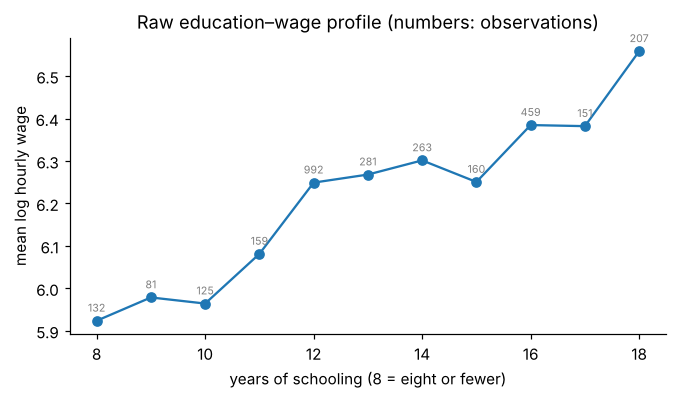

In [4]:
df["ed_level"] = df["ed76"].clip(lower=8)
levels = np.arange(8, 19)
summary = df.groupby("ed_level").agg(n=("lwage76", "size"),
                                     mean_log_wage=("lwage76", "mean"))
summary["raw step"] = summary["mean_log_wage"].diff()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(summary.index, summary["mean_log_wage"], "o-")
for x, n in summary["n"].items():
    ax.annotate(f"{n}", (x, summary.loc[x, "mean_log_wage"]), fontsize=7,
                textcoords="offset points", xytext=(0, 6), ha="center", color="grey")
ax.set(xlabel="years of schooling (8 = eight or fewer)", ylabel="mean log hourly wage",
       title="Raw education–wage profile (numbers: observations)")
plt.show()

## 2. Benchmarks

* **OLS Mincer**: one return to schooling, with experience, experience²,
  race, region and urban indicators (Card's specification) plus family
  background.
* **OLS education dummies**: one dummy per year of schooling, same controls.
* **IV (2SLS)**: Card's strategy. Schooling is instrumented with living
  near a four-year college; experience and its square are instrumented with
  age and age².

In [5]:
rhs = " + ".join(["exp2"] + CONTROLS)
mincer = smf.ols(f"lwage76 ~ ed76 + {rhs}", df).fit(cov_type="HC1")
dummies = smf.ols(f"lwage76 ~ C(ed_level) + {rhs}", df).fit(cov_type="HC1")

exog = " + ".join(c for c in CONTROLS if c != "exp76")
iv = IV2SLS.from_formula(
    f"lwage76 ~ 1 + {exog} + [ed76 + exp76 + exp2 ~ nearc4 + age76 + age2]", df
).fit(cov_type="robust")

benchmarks = pd.DataFrame({
    "return per year": [mincer.params["ed76"], iv.params["ed76"]],
    "s.e.": [mincer.bse["ed76"], iv.std_errors["ed76"]],
}, index=["OLS Mincer", "IV (near 4-year college)"])
benchmarks.round(4)

,return per year,s.e.
OLS Mincer,0.0716,0.0038
IV (near 4-year college),0.1234,0.0503


The IV estimate is much larger than OLS, as in Card (1995), but also much
less precise: its standard error is more than ten times larger.

In [6]:
def dummy_steps(fit):
    """Log-wage step from each year of schooling to the next, with 90% CI."""
    rows = []
    for k in range(1, len(levels)):
        w = pd.Series(0.0, index=fit.params.index)
        w[f"C(ed_level)[T.{levels[k]}]"] = 1.0
        if k > 1:
            w[f"C(ed_level)[T.{levels[k - 1]}]"] = -1.0
        est = float(w @ fit.params)
        sd = float(np.sqrt(w @ fit.cov_params() @ w))
        rows.append((levels[k], est, est - 1.645 * sd, est + 1.645 * sd))
    return pd.DataFrame(rows, columns=["education", "step", "lo", "hi"])


ols_steps = dummy_steps(dummies)

## 3. Bayesian neural network

Inputs: years of schooling plus the 12 controls above. Fitting is the same
as in the CPS notebook (mini-batch ADVI, batches of 100 observations), but
the network is **smaller**: two ReLU hidden layers of 10 units (about 250
weights) instead of three layers of 30 (about 2,300). The next subsection
explains why. We hold out 25% of the sample for an out-of-sample
comparison.

In [7]:
FEATURES = ["ed76"] + CONTROLS
train, test = train_test_split(df, test_size=0.25, random_state=SEED)

x_mean = train[FEATURES].mean().to_numpy()
x_sd = train[FEATURES].std().to_numpy()
y_mean, y_sd = train["lwage76"].mean(), train["lwage76"].std()


def scale(d):
    return (d[FEATURES].to_numpy(float) - x_mean) / x_sd


SMALL = dict(n_layers=2, n_hidden=10)
LARGE = dict(n_layers=3, n_hidden=30)
bnn_small = partial(bm.build_bnn, **SMALL)
bnn_large = partial(bm.build_bnn, **LARGE)

ys_train = ((train["lwage76"] - y_mean) / y_sd).to_numpy()
idata_bnn, hist_bnn = bm.fit_advi(bnn_small, scale(train), ys_train,
                                  n_iter=60_000, batch_size=100, seed=SEED)
idata_large, _ = bm.fit_advi(bnn_large, scale(train), ys_train,
                             n_iter=60_000, batch_size=100, seed=SEED)

# OLS benchmarks fitted on the same training sample
ols_train = smf.ols(f"lwage76 ~ ed76 + {rhs}", train).fit()
dum_train = smf.ols(f"lwage76 ~ C(ed_level) + {rhs}", train).fit()


def bnn_r2(builder, idata, d):
    mu = bm.predict_mu(builder, idata, scale(d))
    return r2_score(d["lwage76"], mu.mean(0) * y_sd + y_mean)


pd.DataFrame({
    "train R²": {"OLS Mincer": ols_train.rsquared,
                 "OLS education dummies": dum_train.rsquared,
                 "BNN 3 × 30": bnn_r2(bnn_large, idata_large, train),
                 "BNN 2 × 10": bnn_r2(bnn_small, idata_bnn, train)},
    "test R²": {"OLS Mincer": r2_score(test["lwage76"], ols_train.predict(test)),
                "OLS education dummies": r2_score(test["lwage76"], dum_train.predict(test)),
                "BNN 3 × 30": bnn_r2(bnn_large, idata_large, test),
                "BNN 2 × 10": bnn_r2(bnn_small, idata_bnn, test)},
}).round(4)

,train R²,test R²
OLS Mincer,0.3049,0.2476
OLS education dummies,0.3116,0.2505
BNN 3 × 30,0.2941,0.2371
BNN 2 × 10,0.3052,0.2548


### Why a small network

The 3 × 30 network used on the CPS fits even the *training* data worse than
a linear regression: it **under-fits**. ADVI maximises the evidence lower
bound, which trades the fit to the data against the divergence from the
prior. The second term grows with the number of weights, the first with the
number of observations. With about 2,300 weights for 2,257 training
observations the prior wins and the network stays too simple. On the CPS,
49,000 observations outweighed the same prior. With about 250 weights the
balance is restored: the BNN fits the training data as well as OLS and
matches it out of sample. Across five seeds (section 5) its test R² is
0.248 ± 0.011, the same as OLS; this seed happens to be one of the better
runs.

The general lesson is that the size of a BNN has to match the sample size.
All the BNNs below use the 2 × 10 architecture.

### Marginal return to each year of schooling

As in the CPS notebook, we set every man's schooling to each level in turn,
keep his other characteristics, average the predicted log wage, and take
differences between consecutive years. Because the sample is small, we
average over the whole data set rather than a subsample.

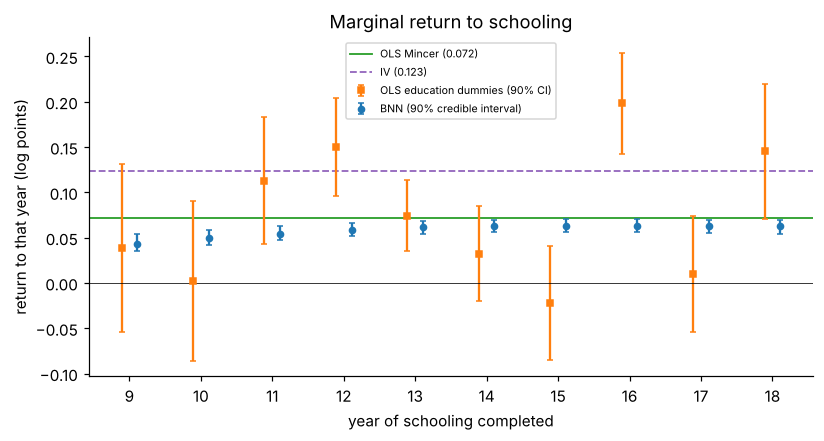

In [8]:
def bnn_steps(builder, idata, ref=df):
    """Posterior draws of the log-wage step from each year to the next."""
    stacked = pd.concat([ref.assign(ed76=float(e)) for e in levels])
    mu = bm.predict_mu(builder, idata, scale(stacked))
    profile = mu.reshape(mu.shape[0], len(levels), len(ref)).mean(axis=2) * y_sd
    return np.diff(profile, axis=1)


def summarise(draws):
    lo, med, hi = np.percentile(draws, [5, 50, 95], axis=0)
    return pd.DataFrame({"education": levels[1:], "step": med, "lo": lo, "hi": hi})


bnn_table = summarise(bnn_steps(bnn_small, idata_bnn))


def plot_steps(ax, tables):
    b, b_iv = mincer.params["ed76"], iv.params["ed76"]
    ax.axhline(b, color="C2", lw=1.2, label=f"OLS Mincer ({b:.3f})")
    ax.axhline(b_iv, color="C4", lw=1.2, ls="--", label=f"IV ({b_iv:.3f})")
    n = len(tables)
    for i, (label, t, style) in enumerate(tables):
        ax.errorbar(t["education"] + (i - (n - 1) / 2) * 0.22, t["step"],
                    yerr=[t["step"] - t["lo"], t["hi"] - t["step"]],
                    capsize=2, ms=4, label=label, **style)
    ax.axhline(0, color="k", lw=0.5)
    ax.set(xlabel="year of schooling completed", xticks=levels[1:])
    ax.legend(fontsize=7)


fig, ax = plt.subplots(figsize=(8.5, 4))
plot_steps(ax, [("OLS education dummies (90% CI)", ols_steps, dict(fmt="s", color="C1")),
                ("BNN (90% credible interval)", bnn_table, dict(fmt="o", color="C0"))])
ax.set(ylabel="return to that year (log points)", title="Marginal return to schooling")
plt.show()

## 4. Ability bias

If more able people both study longer and earn more, part of the OLS
return reflects ability. We compare the return to schooling with and
without the IQ and KWW scores, on the same subsample of 2,040 men, for:

* OLS Mincer;
* the **partially linear BNN**,
  $\log w = \alpha + \beta\,\text{educ} + f(\text{controls}) + \varepsilon$,
  where the network models all controls flexibly.

If the drop in $\beta$ were an artefact of the linear way OLS includes the
controls, the partially linear BNN would show a different drop.

In [9]:
ab = df.dropna(subset=ABILITY).copy()
rows = {}
for label, extra in [("without ability", []), ("with IQ + KWW", ABILITY)]:
    ols_fit = smf.ols(f"lwage76 ~ ed76 + {' + '.join(['exp2'] + CONTROLS + extra)}",
                      ab).fit(cov_type="HC1")
    cols = ["ed76"] + CONTROLS + extra
    Xa = ab[cols].to_numpy(float)
    m_, s_ = Xa.mean(0), Xa.std(0)
    ya_m, ya_s = ab["lwage76"].mean(), ab["lwage76"].std()
    idata_pl, _ = bm.fit_advi(partial(bm.build_partially_linear_bnn, **SMALL),
                              (Xa - m_) / s_,
                              ((ab["lwage76"] - ya_m) / ya_s).to_numpy(),
                              n_iter=60_000, batch_size=100, seed=SEED,
                              linear_cols=(0,))
    beta = idata_pl.posterior["beta"].values.reshape(-1) * ya_s / s_[0]
    rows[("OLS Mincer", label)] = (ols_fit.params["ed76"], ols_fit.bse["ed76"])
    rows[("Partially linear BNN", label)] = (beta.mean(), beta.std())

ability = pd.DataFrame(rows, index=["return per year", "s.e. / posterior sd"]).T
ability

,,return per year,s.e. / posterior sd
OLS Mincer,without ability,0.073681,0.004965
Partially linear BNN,without ability,0.060869,0.004282
OLS Mincer,with IQ + KWW,0.057681,0.005829
Partially linear BNN,with IQ + KWW,0.046341,0.003614


### Dealing with correlated controls: double machine learning

The partially linear BNN estimates $\beta$ and the network $f$ jointly.
Schooling is correlated with several controls (parents' education predicts
their son's schooling), and the network's shrinkage then lets $f$ absorb
part of the education effect. With a joint, regularised fit the estimate
of $\beta$ inherits the regularisation bias of $f$.

**Double machine learning** (Chernozhukov et al., 2018) breaks this link
by separating the two steps:

1. with 5-fold cross-fitting, an ML model predicts log wage from the
   controls, and another predicts schooling from the controls;
2. $\beta$ is the OLS slope of the wage residuals on the schooling
   residuals (the Frisch–Waugh–Lovell logic, with flexible first stages).

Because $\beta$ is identified only from the part of schooling the controls
cannot predict, errors in the control functions affect it only to second
order. We use three ML models: a random forest, gradient boosting and the
**same small BNN**. The BNN version keeps the network for what it is good
at, modelling the controls flexibly, while the orthogonal second step
takes care of the correlation.

In [10]:
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import KFold, cross_val_predict


def dml_beta(data, controls, model):
    """Cross-fitted partialling-out estimate of the return to schooling."""
    X = data[controls].to_numpy(float)
    folds = KFold(5, shuffle=True, random_state=SEED)
    r_y = data["lwage76"] - cross_val_predict(model, X, data["lwage76"], cv=folds)
    r_e = data["ed76"] - cross_val_predict(model, X, data["ed76"], cv=folds)
    fit = smf.ols("r_y ~ r_e - 1", pd.DataFrame({"r_y": r_y, "r_e": r_e})).fit(cov_type="HC1")
    return fit.params["r_e"], fit.bse["r_e"]


def bnn_predict_cv(X, target, folds):
    """Cross-fitted BNN predictions of ``target`` from ``X``."""
    pred = np.empty_like(target)
    for k, (fit_idx, out_idx) in enumerate(folds.split(X)):
        m_, s_ = X[fit_idx].mean(0), X[fit_idx].std(0)
        t_m, t_s = target[fit_idx].mean(), target[fit_idx].std()
        idata, _ = bm.fit_advi(bnn_small, (X[fit_idx] - m_) / s_,
                               (target[fit_idx] - t_m) / t_s,
                               n_iter=30_000, batch_size=100, seed=k)
        mu = bm.predict_mu(bnn_small, idata, (X[out_idx] - m_) / s_)
        pred[out_idx] = mu.mean(0) * t_s + t_m
    return pred


def dml_bnn_beta(data, controls):
    """Double ML estimate with the small BNN as the ML model (10 fits)."""
    X = data[controls].to_numpy(float)
    folds = KFold(5, shuffle=True, random_state=SEED)
    y, e = data["lwage76"].to_numpy(), data["ed76"].to_numpy(float)
    r_y, r_e = y - bnn_predict_cv(X, y, folds), e - bnn_predict_cv(X, e, folds)
    fit = smf.ols("r_y ~ r_e - 1", pd.DataFrame({"r_y": r_y, "r_e": r_e})).fit(cov_type="HC1")
    return fit.params["r_e"], fit.bse["r_e"]


ML = {
    "DML, random forest": RandomForestRegressor(300, min_samples_leaf=20,
                                                random_state=SEED, n_jobs=-1),
    "DML, gradient boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3,
                                                        learning_rate=0.05,
                                                        random_state=SEED),
}
for label, extra in [("without ability", []), ("with IQ + KWW", ABILITY)]:
    for name, model in ML.items():
        rows[(name, label)] = dml_beta(ab, CONTROLS + extra, model)
    rows[("DML, BNN 2 × 10", label)] = dml_bnn_beta(ab, CONTROLS + extra)

res = pd.DataFrame(rows, index=["beta", "se"]).T
est = res["beta"].unstack()[["without ability", "with IQ + KWW"]]
est["s.e. (without)"] = res["se"].unstack()["without ability"]
est["share explained by ability"] = 1 - est["with IQ + KWW"] / est["without ability"]
est.loc[["OLS Mincer", "DML, random forest", "DML, gradient boosting",
         "DML, BNN 2 × 10", "Partially linear BNN"]].round(4)

,without ability,with IQ + KWW,s.e. (without),share explained by ability
OLS Mincer,0.0737,0.0577,0.0050,0.2171
"DML, random forest",0.0723,0.0557,0.0051,0.2307
"DML, gradient boosting",0.0709,0.0574,0.0052,0.1903
"DML, BNN 2 × 10",0.0695,0.0554,0.0050,0.2035
Partially linear BNN,0.0609,0.0463,0.0043,0.2387


## 5. Robustness: nested BNN and run-to-run variation

Same test as in the CPS notebook: we fit the standard and the nested BNN
(both 2 × 10) with five seeds each, compare test R², and pool the draws across runs to
get intervals that also reflect run-to-run variation.

This cell fits nine more networks and takes several minutes.

In [11]:
SEEDS = [0, 1, 2, 3, 4]
BUILDERS = {"BNN": bnn_small, "Nested BNN": partial(bm.build_nested_bnn, **SMALL)}
runs = {name: {} for name in BUILDERS}
runs["BNN"][SEED] = idata_bnn
for name, builder in BUILDERS.items():
    for s in SEEDS:
        if s not in runs[name]:
            runs[name][s], _ = bm.fit_advi(builder, scale(train), ys_train,
                                           n_iter=60_000, batch_size=100, seed=s)

X_test = scale(test)
r2 = pd.DataFrame({
    name: {s: r2_score(test["lwage76"],
                       bm.predict_mu(BUILDERS[name], idata, X_test).mean(0) * y_sd + y_mean)
           for s, idata in runs[name].items()}
    for name in BUILDERS})
r2.index.name = "seed"
r2.loc["mean"] = r2.mean()
r2.loc["sd"] = r2.iloc[:-1].std()
r2.round(4)

,BNN,Nested BNN
seed,,
0,0.2548,0.2430
1,0.2467,0.2152
2,0.2587,0.2539
3,0.2294,0.2473
4,0.2483,0.2318
mean,0.2476,0.2382
sd,0.0113,0.0152


Posterior mean of `model_sel` for each input (0 = ReLU network,
1 = tanh network):

In [12]:
sel = pd.DataFrame(
    {s: idata.posterior["model_sel"].mean(("chain", "draw")).values
     for s, idata in runs["Nested BNN"].items()}, index=FEATURES).T
sel.index.name = "seed"
sel.round(2)

,ed76,exp76,black,south76,smsa76,south66,smsa66,daded,momed,nodaded,momdad14,sinmom14,step14
seed,,,,,,,,,,,,,
0,0.05,0.06,0.23,0.31,0.47,0.88,0.74,0.90,0.92,0.89,0.78,0.86,0.90
1,0.39,0.94,0.14,0.14,0.24,0.77,0.40,0.68,0.82,0.79,0.70,0.78,0.71
2,0.08,0.05,0.36,0.40,0.51,0.91,0.82,0.91,0.87,0.92,0.77,0.87,0.88
3,0.09,0.05,0.37,0.40,0.48,0.90,0.78,0.90,0.88,0.91,0.77,0.87,0.86
4,0.39,0.94,0.14,0.15,0.25,0.77,0.37,0.69,0.82,0.81,0.64,0.79,0.76


BNN, average width of the 90% interval: one run 0.015, five runs pooled 0.020 (1.3x)


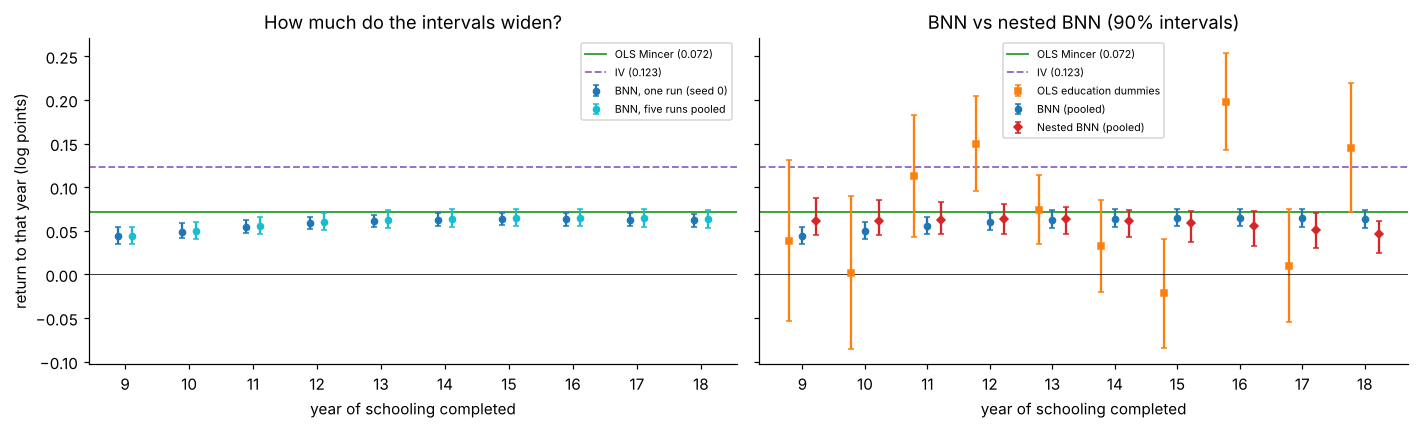

In [13]:
steps = {name: {s: bnn_steps(BUILDERS[name], idata) for s, idata in runs[name].items()}
         for name in BUILDERS}
pooled = {name: summarise(np.concatenate(list(d.values()))) for name, d in steps.items()}
width_single = (bnn_table["hi"] - bnn_table["lo"]).mean()
width_pooled = (pooled["BNN"]["hi"] - pooled["BNN"]["lo"]).mean()
print(f"BNN, average width of the 90% interval: one run {width_single:.3f}, "
      f"five runs pooled {width_pooled:.3f} ({width_pooled / width_single:.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
plot_steps(axes[0], [("BNN, one run (seed 0)", bnn_table, dict(fmt="o", color="C0")),
                     ("BNN, five runs pooled", pooled["BNN"], dict(fmt="o", color="C9"))])
axes[0].set(title="How much do the intervals widen?",
            ylabel="return to that year (log points)")
plot_steps(axes[1], [("OLS education dummies", ols_steps, dict(fmt="s", color="C1")),
                     ("BNN (pooled)", pooled["BNN"], dict(fmt="o", color="C0")),
                     ("Nested BNN (pooled)", pooled["Nested BNN"], dict(fmt="D", color="C3"))])
axes[1].set_title("BNN vs nested BNN (90% intervals)")
plt.tight_layout()
plt.show()

## 6. Takeaways

* **Strong sheepskin effects.** Here schooling is measured in actual years,
  not derived from degrees, so the evidence is cleaner than in the CPS.
  The education dummies show the payoff concentrated in the years that
  complete a degree: about 15 log points for the 12th year (high school),
  20 for the 16th (bachelor's) and 15 for the 18th (graduate degree).
  Most intermediate years (10, 14, 15, 17) add little or nothing. Intervals
  are wide because the sample is small.
* **Network size must match the sample.** The 3 × 30 network that worked on
  the CPS under-fits here: its training R² is below OLS. A 2 × 10 network
  fits as well as OLS (test R² 0.248 ± 0.011 across five seeds, against
  0.248 for Mincer and 0.250 for the dummies). With few observations and an
  almost additive relationship, a BNN can match a well-specified
  regression but has little room to beat it.
* **The BNN still misses the steps.** Even the small network gives a smooth
  profile of about 4.5–6.5% per year. It sees schooling as a continuous
  number, and with this little data it does not pick up the jumps at
  degree years.
* **Correlated controls: the joint fit is biased, double ML fixes it.** The
  partially linear BNN, which fits $\beta$ and the control function
  together, puts the return at 6.1%: the network absorbs part of the
  education effect through controls correlated with schooling. Double
  machine learning, which estimates $\beta$ only from the part of schooling
  the controls cannot predict, gives 6.95% (s.e. 0.50) when the same small
  BNN models the controls. That is in line with random-forest (7.2%),
  gradient-boosting (7.1%) and OLS (7.4%) estimates. Used inside double
  ML, the BNN is a sound tool for estimating a coefficient.
* **Ability bias is robust.** Controlling for IQ and the KWW score lowers
  the return by about a fifth in every method (19–24%; with double ML and a
  BNN, from 6.95% to 5.5% per year).
* **IV.** Using college proximity as an instrument gives 12.3% per year,
  larger than OLS as in Card (1995), but with a standard error of 5
  points. It is also a local effect, for men whose schooling responds to
  having a college nearby, so it is not directly comparable with the OLS
  estimates.
* **The nested BNN is worse and unstable.** Its test R² is lower
  (0.238 ± 0.015 across seeds) and its routing has two distinct solutions:
  in three seeds schooling and experience go to the ReLU network, in the
  other two experience goes to the tanh network. The posterior is
  multimodal, and a single variational fit picks one mode at random.

**Overall**, on this small sample with many correlated controls the BNN is
not the best tool for the shape of the education profile (education dummies
are) or for the average return on its own. But as the flexible first stage
of double machine learning it gives an unbiased return to schooling and
the same ability-bias result as the standard methods.